# Chapter 2: Tabular Q-learning

**Goal:** Solve the pickup-and-deliver task with a plain Q-table.

**Result:** filled in by the cells below (training curve, greedy evaluation over 200 unseen episodes, small hyperparameter sweep).

In [1]:
import sys, json; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, gymnasium as gym
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
from src.qlearning import train_q_learning, evaluate_q, evaluate_random
env = gym.make("Taxi-v4")

## Train

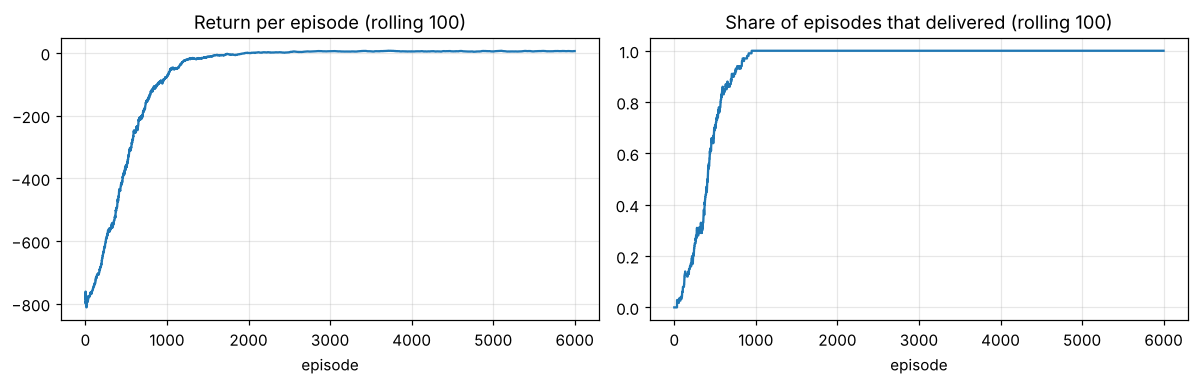

Q-learning greedy: {'mean_return': 8.195, 'mean_steps': 12.805, 'success_rate': 1.0}
random baseline:   {'mean_return': -778.78, 'mean_steps': 197.395, 'success_rate': 0.035}


In [2]:
Q, ret, steps, ok = train_q_learning(env, episodes=6000, alpha=0.1, gamma=0.99, eps_decay=0.999, seed=0)
roll = lambda x, w=100: pd.Series(x).rolling(w, min_periods=1).mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(roll(ret)); ax[0].set(title="Return per episode (rolling 100)", xlabel="episode")
ax[1].plot(roll(ok.astype(float))); ax[1].set(title="Share of episodes that delivered (rolling 100)", xlabel="episode")
plt.tight_layout(); plt.savefig("../docs/img/ch2_q_learning_curve.png"); plt.show()
ev = evaluate_q(env, Q); base = evaluate_random(env)
print("Q-learning greedy:", ev); print("random baseline:  ", base)
json.dump(dict(q_learning=ev, random=base), open("../results/taxi_q.json", "w"))

## Hyperparameter sweep (3000 episodes each, evaluated greedily on 200 unseen episodes)

In [3]:
rows = []
for alpha in [0.05, 0.1, 0.3]:
    for gamma in [0.9, 0.99]:
        Qs, *_ = train_q_learning(env, episodes=3000, alpha=alpha, gamma=gamma, eps_decay=0.998, seed=1)
        e = evaluate_q(env, Qs); rows.append(dict(alpha=alpha, gamma=gamma, **e))
sweep = pd.DataFrame(rows).round(2); print(sweep.to_string(index=False))
sweep.to_csv("../results/taxi_q_sweep.csv", index=False)

 alpha  gamma  mean_return  mean_steps  success_rate
  0.05   0.90       -56.70       71.09          0.68
  0.05   0.99       -37.10       53.48          0.78
  0.10   0.90         1.04       19.22          0.96
  0.10   0.99         6.16       14.64          0.99
  0.30   0.90         8.18       12.82          1.00
  0.30   0.99         8.18       12.82          1.00


## Takeaways
- A plain Q-table solves Taxi: **100% of 200 unseen episodes delivered, 12.8 steps on average, mean return 8.2**, against ~3% for random.
- Learning rate mattered most in the sweep: alpha=0.3 reached 100% success; alpha=0.05 was still at 68-78% after 3,000 episodes. That is under-training, not a worse method.
- Caveat: the sweep uses one seed per setting, so treat small differences as noise.